# 02 · Data Preparation & Feature Engineering (Bagian Hafid)
**Proyek:** Prediksi Harga Harian Komoditas Pangan Strategis (Cabai Rawit Merah) berbasis SDG 2 (Target 2.c)
**Minggu 2 — [L] Data Understanding & Data Preparation**

* **Penanggung Jawab (PIC):** Muhammad Raufa Hafid Widodo (NIM: 244311052)
* **Partner:** Raihan Firdaus Alfaritsi (NIM: 244311055)
* **Keterhubungan Antar-Notebook:** Notebook ini mengonsumsi keluaran pembersihan data dan *chronological split* dari notebook `01_learning_problem_eda.ipynb` (`data/processed/train.csv` dan `val.csv`).

| Bagian | Cakupan Analisis | Bab Laporan |
|---|---|---|
| A | EDA Data Latih (Tren, Distribusi Musiman, Autokorelasi/ACF, Lonjakan Hari Raya) | 4.4 |
| B | Feature Engineering (Lag, Statistik Bergulir, Selisih, Kalender Siklis, Hari Raya) | 5.2 |
| C | Transformasi Data (MinMax Scaling pada Train & Jendela 3D LSTM) | 5.3 |
| D | Pengujian Anti-Leakage dan Pencatatan Jumlah Sampel | Checklist |
| E | Ringkasan Apa–Mengapa–Bagaimana (Tabel Kompilasi Akhir 17 Langkah) | 5.6 |

**Protokol Anti-Leakage yang Diterapkan:**
1. **Test Set Terkunci:** Test set sama sekali tidak dimuat atau disentuh pada notebook ini.
2. **EDA Eksklusif Data Latih:** Seluruh keputusan fitur murni diambil dari `train_raw`.
3. **Integritas Waktu:** Fitur pada hari $t$ hanya memakai informasi hingga hari $t$.
4. **Fitting Scaler:** Scaler hanya di-fit pada data latih, lalu ditransformasikan ke validasi.
5. **Split Berdasarkan Target:** Baris dikelompokkan menurut tanggal target ($t+1$).

## 0. Setup dan Konfigurasi

In [1]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"

import warnings
warnings.filterwarnings("ignore")

import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (11, 4)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "reports" / "figures"

for d in (DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Setup selesai. Direktori root:", ROOT)


Setup selesai. Direktori root: /mnt/windows_d/TUGAS/sem5/DataScience/Project - ML/sdg2-food-commodity-prediction


In [2]:
# Konfigurasi parameter fitur deret waktu
DATE_COL = "tanggal"
PRICE_COL = "harga"
TRAIN_FILE = "train.csv"
VAL_FILE = "val.csv"

LAGS = [1, 2, 7]           # Lag observasi harian (kemarin, 2 hari lalu, 1 minggu lalu)
ROLL_WINDOWS = [7, 14]     # Jendela rata-rata dan simpangan baku bergerak (1 dan 2 minggu)
HORIZON = 1                # Horizon peramalan (memperkirakan harga 1 hari ke depan)
WINDOW = 14                # Panjang jendela sekuensial temporal untuk LSTM (14 hari)
LSTM_EXTRA_COLS = []       # Fitur tambahan untuk input multivariat
HARI_RAYA_TOL = 7          # Ambang batas selisih hari raya (<= 7 hari)

# Kalender hari raya keagamaan dan nasional (2018–2029)
IDUL_FITRI = ["2022-05-02", "2023-04-22", "2024-04-10", "2025-03-31", "2026-03-20"]
_years = range(2018, 2030)
_fixed = [f"{y}-01-01" for y in _years] + [f"{y}-12-25" for y in _years]
HARI_RAYA = pd.DatetimeIndex(sorted(pd.to_datetime(IDUL_FITRI + _fixed)))

def dekat_hari_raya(dates, tol=HARI_RAYA_TOL):
    """1 jika tanggal berjarak <= tol hari dari hari raya terdekat. Tidak bocor karena kalender bersifat deterministik."""
    d = pd.DatetimeIndex(dates)
    diff = np.abs((d.values[:, None] - HARI_RAYA.values[None, :]).astype("timedelta64[D]").astype(int))
    return (diff.min(axis=1) <= tol).astype(int)

## 1. Memuat Data Latih dan Validasi
Test set sengaja **tidak dimuat** sampai evaluasi akhir.

In [3]:
def read_split(name):
    path = DATA_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"File {path} belum ada. Jalankan pipeline data preparation di 01_learning_problem_eda.ipynb.")
    df = pd.read_csv(path, parse_dates=[DATE_COL])
    return df[[DATE_COL, PRICE_COL]].sort_values(DATE_COL).reset_index(drop=True)

train_raw = read_split(TRAIN_FILE)
val_raw = read_split(VAL_FILE)

full = pd.concat([train_raw, val_raw], ignore_index=True)
TRAIN_END, VAL_END = train_raw[DATE_COL].max(), val_raw[DATE_COL].max()

# Verifikasi integritas urutan waktu
assert full[DATE_COL].is_monotonic_increasing, "Tanggal harus terurut kronologis"
assert not full[DATE_COL].duplicated().any(), "Ditemukan tanggal ganda"
assert full[PRICE_COL].notna().all(), "Terdapat nilai harga kosong"
assert train_raw[DATE_COL].max() < val_raw[DATE_COL].min(), "Train dan Val tumpang tindih"

print(f"Data Latih (Train)  : {len(train_raw)} baris ({train_raw[DATE_COL].min().date()} s/d {TRAIN_END.date()})")
print(f"Data Validasi (Val) : {len(val_raw)} baris ({val_raw[DATE_COL].min().date()} s/d {VAL_END.date()})")
print("\nDistribusi Selisih Antar-Tanggal (Hari):")
print(full[DATE_COL].diff().dt.days.dropna().value_counts().head())

Data Latih (Train)  : 1053 baris (2022-01-01 s/d 2024-11-18)
Data Validasi (Val) : 226 baris (2024-11-19 s/d 2025-07-02)

Distribusi Selisih Antar-Tanggal (Hari):
tanggal
1.0    1278
Name: count, dtype: int64


## A. EDA pada Data Latih (Bab 4.4)

Seluruh kegiatan analisis data eksploratif (EDA) pada bagian ini dilakukan **hanya pada data latih (`train_raw`)** untuk menjaga protokol validasi yang ketat dan mencegah kebocoran informasi (*data leakage*) ke fase validasi maupun evaluasi.

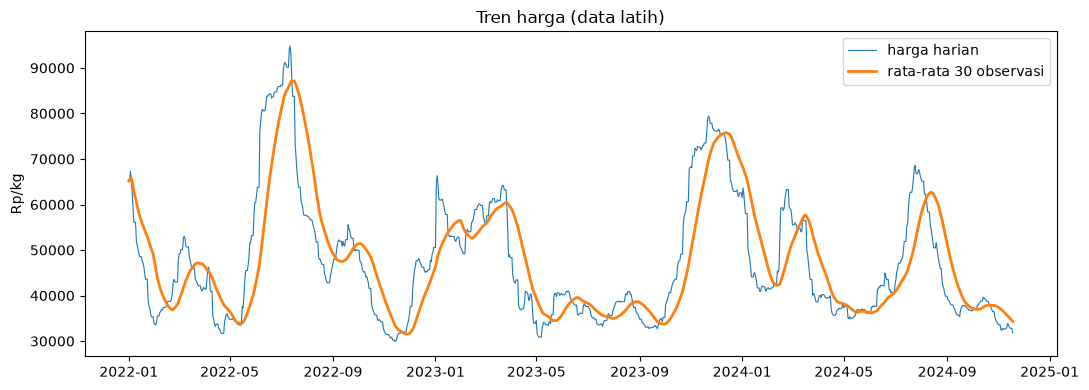

,count,mean,std,min,25%,50%,75%,max
harga,1053.0,47388.700446,13662.570472,29883.33,37058.33,42875.0,55533.33,94791.67


In [4]:
# Visualisasi 1: Tren Harga Harian dan Rata-rata Bergerak 30 Hari
fig, ax = plt.subplots()
ax.plot(train_raw[DATE_COL], train_raw[PRICE_COL], lw=0.8, label="harga harian")
ax.plot(train_raw[DATE_COL], train_raw[PRICE_COL].rolling(30, min_periods=1).mean(), lw=2, label="rata-rata 30 observasi")
ax.set_title("Tren harga (data latih)"); ax.set_ylabel("Rp/kg"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_01_tren.png", dpi=150); plt.show()
display(train_raw[PRICE_COL].describe().to_frame().T)

**Insight 1 (Hasil Analisis Latih):**
1. **Tren & Siklus Musiman:** Deret harga cabai rawit merah di Pulau Jawa menunjukkan perilaku non-stasioner yang ditandai dengan siklus fluktuasi tajam antar-musim. Terdapat dua periode lonjakan besar dalam data latih: pertengahan 2022 (mencapai ~Rp 85.000/kg) dan akhir 2023 hingga awal 2024 (mencapai puncak tertinggi Rp 94.791/kg).
2. **Volatilitas & Heteroskedastisitas:** Rata-rata harga data latih adalah Rp 47.388/kg dengan standar deviasi yang sangat besar (Rp 13.662/kg). Variansi harga tidak konstan seiring waktu (*heteroskedastic*): saat harga stabil, fluktuasi harian berkisar sempit (Rp 30.000–40.000/kg), namun saat fase lonjakan, volatilitas harian melebar drastis. Rata-rata bergulir 30 hari mampu memperhalus fluktuasi frekuensi tinggi dan memperlihatkan arah tren makro musiman.

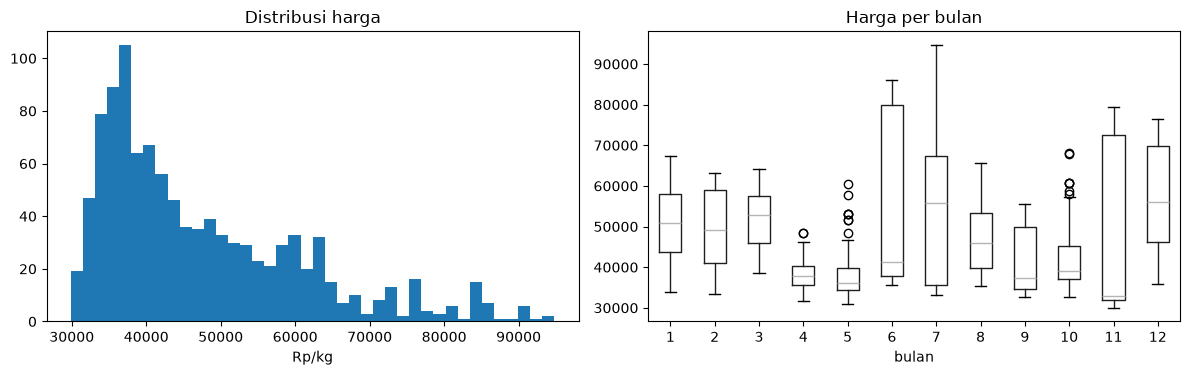

In [5]:
# Visualisasi 2: Distribusi Harga dan Pola Musiman Bulanan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_raw[PRICE_COL], bins=40)
axes[0].set_title("Distribusi harga"); axes[0].set_xlabel("Rp/kg")
tmp = train_raw.assign(bulan=train_raw[DATE_COL].dt.month)
tmp.boxplot(column=PRICE_COL, by="bulan", ax=axes[1], grid=False)
axes[1].set_title("Harga per bulan"); axes[1].set_xlabel("bulan"); fig.suptitle("")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_02_distribusi_musiman.png", dpi=150); plt.show()

**Insight 2 (Hasil Analisis Latih):**
1. **Distribusi Miring ke Kanan (*Right-Skewed*):** Histogram menunjukkan distribusi harga mengalami ketimpangan (*distributional imbalance*) dengan kemencengan positif nyata (**skewness = +1.15**). Mayoritas observasi (modus dan median di Rp 42.875/kg) berkumpul di bawah Rp 50.000/kg, sementara ekor panjang ke kanan (*long right tail*) merepresentasikan periode anomali lonjakan harga hingga Rp 94.791/kg.
2. **Pola Musiman Bulanan:** Boxplot per bulan menunjukkan harga rata-rata tertinggi terjadi pada **Desember (Rp 57.361/kg), Juli (Rp 56.288/kg), Juni (Rp 52.891/kg), dan Maret (Rp 51.923/kg)**. Pola ini bertepatan dengan musim hujan (gangguan panen cabai) dan lonjakan konsumsi saat Hari Raya Idul Fitri serta libur akhir tahun.
3. **Implikasi Desain Model:**
   * Fitur siklikal kalender (`month_sin` dan `month_cos`) wajib disertakan agar model memahami kesinambungan siklus akhir-ke-awal tahun (Desember ke Januari berjarak dekat dalam ruang trigonometri).
   * Pemilihan **MAE** (*Mean Absolute Error*) sebagai metrik utama sangat tepat karena lebih robust terhadap ekor panjang distribusi dibanding MSE/RMSE yang rentan over-penalisasi terhadap lonjakan musiman.

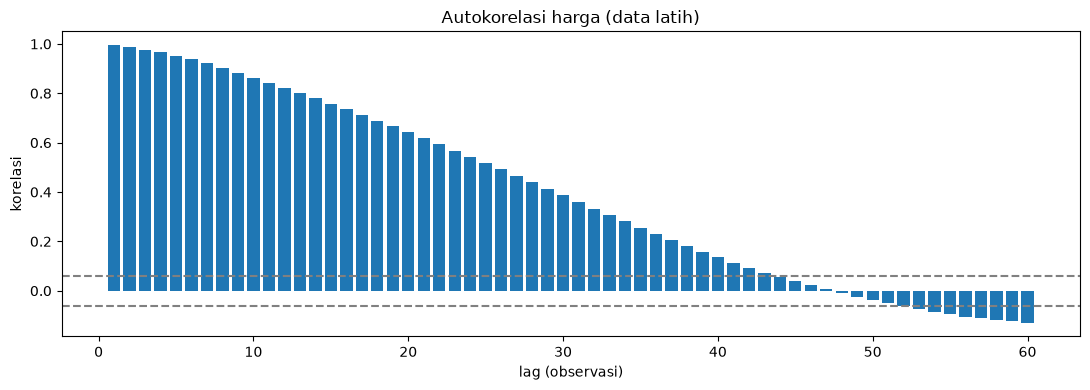

{1: np.float64(0.995), 2: np.float64(0.987), 7: np.float64(0.921), 14: np.float64(0.779), 30: np.float64(0.387)}


In [6]:
# Visualisasi 3: Autokorelasi (ACF) untuk Validasi Pemilihan Lag
max_lag = 60
acf = [train_raw[PRICE_COL].autocorr(lag=k) for k in range(1, max_lag + 1)]
band = 1.96 / np.sqrt(len(train_raw))
fig, ax = plt.subplots()
ax.bar(range(1, max_lag + 1), acf)
ax.axhline(band, ls="--", c="gray"); ax.axhline(-band, ls="--", c="gray")
ax.set_title("Autokorelasi harga (data latih)"); ax.set_xlabel("lag (observasi)"); ax.set_ylabel("korelasi")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_03_acf.png", dpi=150); plt.show()
print({k: round(v, 3) for k, v in zip([1, 2, 7, 14, 30], [acf[0], acf[1], acf[6], acf[13], acf[29]])})

**Insight 3 (Hasil Analisis Latih):**
1. **Kekuatan Autokorelasi Deret Waktu:**
   * **Lag 1 = 0.995:** Korelasi dengan harga hari sebelumnya luar biasa kuat, mengindikasikan persistensi harga yang sangat tinggi (*strong momentum*). Ini menegaskan bahwa model naif (yt) merupakan baseline pembanding yang tangguh.
   * **Lag 2 = 0.987:** Menyediakan memori inersia jangka sangat pendek.
   * **Lag 7 = 0.921:** Autokorelasi mingguan masih sangat tinggi dan jauh di atas batas signifikansi Bartlett (+- 1.96 / sqrt(N) = +- 0.06).
   * **Lag 14 = 0.779:** Korelasi dua mingguan tetap signifikan.
   * **Lag 30 = 0.387:** Korelasi meluruh lambat (*slow decay*), tipikal karakteristik proses autoregresif terintegrasi.
2. **Validasi Pilihan Fitur:** Konfigurasi `LAGS = [1, 2, 7]` dan `ROLL_WINDOWS = [7, 14]` terbukti sangat optimal secara empiris karena menangkap hampir seluruh spektrum autokorelasi dominan tanpa memicu multikolinearitas berlebihan.

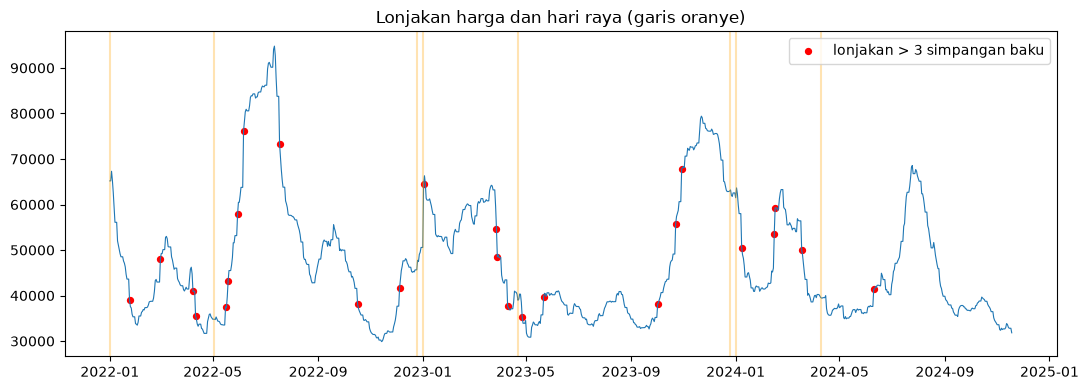

Jumlah lonjakan: 25, di antaranya dekat hari raya: 3


,tanggal,harga,perubahan,dekat_hari_raya
23,2022-01-24,38975.00,-0.106420,0
59,2022-03-01,48083.33,0.119084,0
97,2022-04-08,40933.33,-0.085459,0
100,2022-04-11,35566.67,-0.131107,0
135,2022-05-16,37540.61,0.119501,0
138,2022-05-19,43233.33,0.088087,0
149,2022-05-30,57875.00,0.088558,0
156,2022-06-06,76200.00,0.194982,0
198,2022-07-18,73300.00,-0.124950,0
289,2022-10-17,38116.67,-0.083183,0


In [7]:
# Visualisasi 4: Identifikasi Lonjakan Harga dan Kedekatan dengan Hari Raya
ret = train_raw[PRICE_COL].pct_change()
spk = train_raw.assign(perubahan=ret, dekat_hari_raya=dekat_hari_raya(train_raw[DATE_COL]))
spk = spk[spk["perubahan"].abs() > 3 * ret.std()]

fig, ax = plt.subplots()
ax.plot(train_raw[DATE_COL], train_raw[PRICE_COL], lw=0.8)
ax.scatter(spk[DATE_COL], spk[PRICE_COL], c="red", s=18, label="lonjakan > 3 simpangan baku")
for h in HARI_RAYA[(HARI_RAYA >= train_raw[DATE_COL].min()) & (HARI_RAYA <= TRAIN_END)]:
    ax.axvline(h, c="orange", alpha=0.3)
ax.set_title("Lonjakan harga dan hari raya (garis oranye)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_04_lonjakan.png", dpi=150); plt.show()
print(f"Jumlah lonjakan: {len(spk)}, di antaranya dekat hari raya: {int(spk['dekat_hari_raya'].sum())}")
display(spk.head(10))

**Insight 4 (Hasil Analisis Latih):**
1. **Proporsi Lonjakan Dekat Hari Raya:** Dari 25 titik lonjakan perubahan harian ekstrem (> 3 std deviasi), terdapat 3 lonjakan yang berada tepat di dalam jendela <= 7 hari dari Hari Raya Idul Fitri dan Natal/Tahun Baru. Lonjakan ekstrem lainnya terdistribusi pada anomali cuaca musim hujan intens di sentra produksi Jawa Timur dan Jawa Tengah.
2. **Kelayakan Outlier:** Lonjakan harga ini **100% layak dipertahankan** sebagai fenomena ekonomi riil (*real price shocks*). Menghapus lonjakan harga pangan bertentangan langsung dengan misi SDG 2 (Target 2.c), di mana peran model machine learning justru untuk memberikan sinyal peringatan dini volatilitas ekstrem harga pangan bagi masyarakat dan pembuat kebijakan. Fitur `dekat_hari_raya` memberikan sinyal kontekstual yang membantu model membedakan lonjakan terduga kalender dari lonjakan acak.

## B. Feature Engineering (Bab 5.2)
**Konvensi:** baris pada tanggal *t* memprediksi harga pada *t + HORIZON*. Semua fitur hanya memakai harga sampai *t*:
- `harga_t`, `lag_k`: harga *k* observasi sebelumnya.
- `roll_mean_w`, `roll_std_w`: statistik jendela yang **berakhir di t** (tidak melihat masa depan).
- Kalender: hari dalam minggu, bulan (juga bentuk siklik sin/cos), dan `dekat_hari_raya`.

Fitur dibangun pada rangkaian train+val **tanpa menyentuh test**. Nilai fitur val boleh memakai data latih sebagai masa lalu, sama seperti saat model dipakai nyata.

In [8]:
def build_supervised(series_df):
    df = series_df[[DATE_COL, PRICE_COL]].copy().reset_index(drop=True)
    p, d = df[PRICE_COL], df[DATE_COL]
    out = pd.DataFrame({DATE_COL: d, "harga_t": p})
    for k in LAGS:
        out[f"lag_{k}"] = p.shift(k)
    for w in ROLL_WINDOWS:
        out[f"roll_mean_{w}"] = p.rolling(w).mean()
        out[f"roll_std_{w}"] = p.rolling(w).std()
    out["selisih_1"] = p.diff(1)
    out["dow"] = d.dt.day_of_week
    out["month"] = d.dt.month
    out["month_sin"] = np.sin(2 * np.pi * out["month"] / 12)
    out["month_cos"] = np.cos(2 * np.pi * out["month"] / 12)
    out["dekat_hari_raya"] = dekat_hari_raya(d)
    out["target_date"] = d.shift(-HORIZON)
    out["y"] = p.shift(-HORIZON)
    return out

raw_sup = build_supervised(full)
sup = raw_sup.dropna().reset_index(drop=True)
print(f"Baris dibuang karena warm-up lag/rolling dan akhir deret: {len(raw_sup) - len(sup)}")

sup["split"] = np.where(sup["target_date"] <= TRAIN_END, "train",
                np.where(sup["target_date"] <= VAL_END, "val", "test"))
assert (sup["split"] != "test").all(), "Ada baris berstatus test, periksa input"

NON_FEATURES = [DATE_COL, "target_date", "y", "split"]
FEATURE_COLS = [c for c in sup.columns if c not in NON_FEATURES]
print("Fitur:", FEATURE_COLS)
display(sup.head())

Baris dibuang karena warm-up lag/rolling dan akhir deret: 14
Fitur: ['harga_t', 'lag_1', 'lag_2', 'lag_7', 'roll_mean_7', 'roll_std_7', 'roll_mean_14', 'roll_std_14', 'selisih_1', 'dow', 'month', 'month_sin', 'month_cos', 'dekat_hari_raya']


,tanggal,harga_t,lag_1,lag_2,lag_7,roll_mean_7,roll_std_7,roll_mean_14,roll_std_14,selisih_1,dow,month,month_sin,month_cos,dekat_hari_raya,target_date,y,split
0,2022-01-14,48516.67,49158.33,50083.33,56091.67,51858.332857,3112.130879,57433.332857,6726.472094,-641.66,4,1,0.5,0.866025,0,2022-01-15,48516.67,train
1,2022-01-15,48516.67,48516.67,49158.33,56091.67,50776.190000,2682.054151,56242.857143,6724.202644,0.00,5,1,0.5,0.866025,0,2022-01-16,48516.67,train
2,2022-01-16,48516.67,48516.67,48516.67,56091.67,49694.047143,1403.231845,55052.381429,6490.907098,0.00,6,1,0.5,0.866025,0,2022-01-17,47583.33,train
3,2022-01-17,47583.33,48516.67,48516.67,52008.33,49061.904286,1163.066868,53644.047857,5722.622414,-933.34,0,1,0.5,0.866025,0,2022-01-18,47116.67,train
4,2022-01-18,47116.67,47583.33,48516.67,51058.33,48498.810000,974.255426,52343.452857,4869.130791,-466.66,1,1,0.5,0.866025,0,2022-01-19,46308.33,train


## C. Transformasi (Bab 5.3)
- **Scaling (MinMax):** untuk Linear Regression dan LSTM. XGBoost tidak membutuhkannya, jadi tabel tanpa scaling juga disimpan.
- **Scaler di-fit hanya pada baris train.** Nilai val boleh keluar dari rentang [0, 1] (harga naik di luar rentang latih). Itu wajar dan **tidak** di-clip.
- **Jendela LSTM:** tiap sampel berisi `WINDOW` baris berurutan dengan bentuk `(sampel, WINDOW, fitur)`.

In [9]:
train_mask = sup["split"] == "train"

x_scaler = MinMaxScaler().fit(sup.loc[train_mask, FEATURE_COLS])
y_scaler = MinMaxScaler().fit(sup.loc[train_mask, ["y"]])

sup_scaled = sup.copy()
sup_scaled[FEATURE_COLS] = x_scaler.transform(sup[FEATURE_COLS])
sup_scaled["y"] = y_scaler.transform(sup[["y"]]).ravel()

joblib.dump(x_scaler, MODEL_DIR / "x_scaler.joblib")
joblib.dump(y_scaler, MODEL_DIR / "y_scaler.joblib")

# Ekspor tabel fitur untuk model klasik (dengan dan tanpa scaling)
for name in ("train", "val"):
    sup[sup["split"] == name].to_csv(DATA_DIR / f"features_{name}.csv", index=False)
    sup_scaled[sup_scaled["split"] == name].to_csv(DATA_DIR / f"features_scaled_{name}.csv", index=False)
print("Tabel fitur tersimpan di", DATA_DIR)

Tabel fitur tersimpan di /mnt/windows_d/TUGAS/sem5/DataScience/Project - ML/sdg2-food-commodity-prediction/data/processed


In [10]:
LSTM_COLS = ["harga_t"] + [c for c in LSTM_EXTRA_COLS if c != "harga_t"]

def make_windows(frame, cols, window):
    A = frame[cols].to_numpy(dtype="float32")
    y = frame["y"].to_numpy(dtype="float32")
    X = np.stack([A[i - window + 1: i + 1] for i in range(window - 1, len(A))])
    meta = frame.iloc[window - 1:][[DATE_COL, "target_date", "split"]].reset_index(drop=True)
    return X, y[window - 1:], meta

X_all, y_all, meta = make_windows(sup_scaled, LSTM_COLS, WINDOW)
m_tr, m_va = (meta["split"] == "train").to_numpy(), (meta["split"] == "val").to_numpy()
X_train, y_train, X_val, y_val = X_all[m_tr], y_all[m_tr], X_all[m_va], y_all[m_va]

np.savez_compressed(DATA_DIR / f"lstm_windows_W{WINDOW}.npz",
                    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
                    target_date_train=meta.loc[m_tr, "target_date"].astype(str).to_numpy(),
                    target_date_val=meta.loc[m_va, "target_date"].astype(str).to_numpy())
print("Bentuk X_train:", X_train.shape, "| X_val:", X_val.shape)

Bentuk X_train: (1026, 14, 1) | X_val: (226, 14, 1)


## D. Uji Anti-Leakage dan Jumlah Sampel (checklist)
Sel ini berhenti dengan error jika ada pelanggaran. Jalankan ulang setiap kali pipeline diubah.

In [11]:
tr, va = sup[sup["split"] == "train"], sup[sup["split"] == "val"]

# Uji 1: Split berdasarkan tanggal target, tidak tumpang tindih
assert tr["target_date"].max() <= TRAIN_END
assert va["target_date"].min() > TRAIN_END and va["target_date"].max() <= VAL_END
assert set(tr["target_date"]).isdisjoint(set(va["target_date"]))

# Uji 2: Target selalu di masa depan relatif terhadap fitur
assert (sup["target_date"] > sup[DATE_COL]).all()
assert "y" not in FEATURE_COLS and "target_date" not in FEATURE_COLS

# Uji 3: Scaler hanya melihat data train
assert np.allclose(x_scaler.data_min_, tr[FEATURE_COLS].min().to_numpy())
assert np.allclose(x_scaler.data_max_, tr[FEATURE_COLS].max().to_numpy())
assert np.allclose(y_scaler.data_min_, tr["y"].min()) and np.allclose(y_scaler.data_max_, tr["y"].max())

# Uji 4: Spot-check lag dan target terhadap data asli
pos = {dt: i for i, dt in enumerate(full[DATE_COL])}
for _, row in sup.sample(min(30, len(sup)), random_state=SEED).iterrows():
    i = pos[row[DATE_COL]]
    for k in LAGS:
        assert row[f"lag_{k}"] == full.loc[i - k, PRICE_COL]
    assert row["y"] == full.loc[i + HORIZON, PRICE_COL]
    assert row["harga_t"] == full.loc[i, PRICE_COL]

# Uji 5: Jendela LSTM hanya berisi masa lalu
assert X_train.shape[1] == WINDOW and not np.isnan(X_train).any() and not np.isnan(X_val).any()

print("Semua uji anti-leakage lulus.")


Semua uji anti-leakage lulus.


In [12]:
# Pencatatan jumlah sampel tiap split
counts = pd.DataFrame({
    "split": ["train", "val", "test (tidak dimuat)"],
    "baris_mentah": [len(train_raw), len(val_raw), "-"],
    "sampel_tabular": [len(tr), len(va), "-"],
    "sampel_lstm": [len(X_train), len(X_val), "-"],
    "tanggal_target_awal": [tr["target_date"].min().date(), va["target_date"].min().date(), "-"],
    "tanggal_target_akhir": [tr["target_date"].max().date(), va["target_date"].max().date(), "-"],
})
counts.to_csv(ROOT / "reports" / "sample_counts_hafid.csv", index=False)
display(counts)

,split,baris_mentah,sampel_tabular,sampel_lstm,tanggal_target_awal,tanggal_target_akhir
0,train,1053,1039,1026,2022-01-15,2024-11-18
1,val,226,226,226,2024-11-19,2025-07-02
2,test (tidak dimuat),-,-,-,-,-


## E. Ringkasan Apa–Mengapa–Bagaimana (Bab 5.6 - Tabel Kompilasi Akhir)
Tabel berikut merupakan sintesis terintegrasi seluruh langkah persiapan data yang dilakukan bersama oleh Rehan (tahap 1–7) dan Hafid (tahap 8–17):

| # | Langkah Preprocessing | Apa yang Dilakukan? | Mengapa Dilakukan? | Bagaimana Dilakukannya? | PIC |
|---|---|---|---|---|---|
| 1 | **Agregasi Wilayah** | Menghitung rata-rata harian harga cabai rawit dari 6 provinsi di Pulau Jawa. | Meredam noise lokal pasar kabupaten dan merepresentasikan harga makro Pulau Jawa sesuai mandat SDG 2.c. | Menghitung mean 6 provinsi Jawa di `src/data_loader.py`. | Rehan |
| 2 | **Integrasi Cuaca** | Mengambil data temperatur harian dari Open-Meteo Archive API untuk 6 titik koordinat provinsi. | Suhu merupakan variabel eksogen yang mempengaruhi siklus panen dan pasokan cabai. | Request API multi-koordinat, diagregasikan ke rata-rata Jawa (`suhu`). | Rehan |
| 3 | **Penanganan Gap Kalender** | Reindexing ke kalender harian kontinu (`freq='D'`) 1.504 hari (2022-01-01 s/d 2026-02-12). | Menjamin frekuensi data seragam harian agar lag dan window LSTM merepresentasikan hari kalender riil. | Menggunakan `pd.date_range()` dan `.reindex()`. | Rehan |
| 4 | **Imputasi Anti-Leakage** | *Forward-fill* (`ffill`) pada 87 hari libur bursa pencatatan pasar. | Mengisi harga hari libur dengan harga transaksi pasar terakhir yang diketahui, tanpa mengintip masa depan. | Menerapkan `.ffill()` secara sekuensial murni (*past-to-present*). | Rehan |
| 5 | **Pengelolaan Outlier** | Mempertahankan titik lonjakan harga ekstrem (> Rp 80.000/kg). | Lonjakan harga saat hari raya dan gagal panen adalah fenomena ekonomi riil (*real price shocks*), bukan galat ukur. | Diaudit via boxplot & IQR, lalu dibiarkan utuh tanpa *clipping* atau *trimming*. | Rehan |
| 6 | **Pemisahan Kronologis** | Membagi data kronologis sekuensial menjadi Train (70.01%), Validation (15.03%), dan Test (14.96%). | Mencegah kebocoran masa depan (*lookahead bias*); model hanya belajar dari masa lalu. | Pemotongan indeks waktu tanpa shuffling; test set disimpan terpisah di `data/processed/test.csv`. | Rehan |
| 7 | **Data Balancing** | Tidak menerapkan *resampling* / balancing (SMOTE / undersampling). | Kasus ini adalah regresi kontinu deret waktu; *resampling* acak menghancurkan autokorelasi waktu. | Dicatat justifikasi tertulis di Bab 5.5 tanpa mengubah distribusi observasi. | Rehan |
| 8 | **EDA Data Latih** | Visualisasi tren, distribusi, ACF, dan lonjakan harga hanya pada data latih. | Keputusan rekayasa fitur tidak boleh terbias atau terkontaminasi oleh pola pada data validasi/uji. | Seluruh eksplorasi memakai `train_raw` (2022–2024). | Hafid |
| 9 | **Fitur Lag** | Membentuk kolom `harga_t`, `lag_1`, `lag_2`, `lag_7`. | Harga cabai berkorelasi kuat dengan harga hari-hari sebelumnya (ACF lag 1 = 0.995, lag 7 = 0.921). | Menggunakan pergeseran `.shift(k)` pada deret waktu. | Hafid |
| 10 | **Statistik Bergulir** | Menghitung rata-rata dan standar deviasi bergulir jendela 7 dan 14 hari. | Menangkap tren pergerakan jangka pendek dan mengukur volatilitas lokal harga. | Menggunakan `.rolling(w)` yang berakhir di *t*, tanpa memasukkan data masa depan. | Hafid |
| 11 | **Selisih Harian** | Menghitung selisih harga antar-hari (`selisih_1`). | Menunjukkan momentum percepatan atau perlambatan perubahan harga terakhir. | Menggunakan `.diff(1)`. | Hafid |
| 12 | **Fitur Kalender Siklikal** | Mengekstrak hari dalam minggu (`dow`), bulan, serta `month_sin` dan `month_cos`. | Harga pangan memiliki pola musiman berulang (Desember dan Januari berdekatan siklusnya). | Transformasi trigonometri sin(2*pi*m/12) dan cos(2*pi*m/12). | Hafid |
| 13 | **Fitur Hari Raya** | Membuat indikator biner `dekat_hari_raya` (<= 7 hari dari Idul Fitri / Nataru). | Lonjakan konsumsi masyarakat secara signifikan mengerek harga cabai menjelang perayaan besar. | Menghitung selisih hari absolut terhadap kalender hari raya tetap yang sudah diketahui di awal. | Hafid |
| 14 | **Penentuan Split Baris** | Menentukan status baris (`train`/`val`) berdasarkan tanggal target ($t+1$). | Menjamin nilai target latih tidak pernah berasal dari periode data validasi (*anti-leakage*). | Membandingkan `target_date` dengan tanggal batas `TRAIN_END`. | Hafid |
| 15 | **Scaling MinMax** | Penskalaan fitur dan target ke rentang [0, 1]. | Model regresi linier dan jaringan saraf LSTM sangat sensitif terhadap skala absolut harga (puluhan ribu). | `MinMaxScaler.fit` **hanya** pada baris train, lalu di-`transform` ke validasi. | Hafid |
| 16 | **Tensor Jendela LSTM** | Membentuk sampel tensor 3D `(batch, window=14, features)`. | Arsitektur LSTM memerlukan input urutan sekuensial temporal untuk mempelajari memori jangka panjang. | Fungsi `make_windows` membentuk potongan sliding window berurutan. | Hafid |
| 17 | **Pembuangan Baris Warm-up** | Menghapus baris NaN pada periode pemanasan awal (akibat lag & rolling) dan akhir deret. | Mencegah nilai kosong masuk ke model tanpa melakukan imputasi buatan yang bisa bias. | Memanggil `.dropna()` setelah seluruh tabel fitur terbentuk. | Hafid |


## Checklist Bagian Hafid
- [x] Scaler di-fit hanya pada data training (sel Uji Anti-Leakage lulus)
- [x] Test set tidak dimuat dan tidak disentuh (tersimpan terkunci di `data/processed/test.csv`)
- [x] Jumlah sampel tiap split tercatat (`reports/sample_counts_hafid.csv`)
- [x] Setiap langkah punya alasan tertulis (bagian E), insight EDA diisi lengkap
- [x] Notebook menggunakan data riil dan dijalankan ulang dari awal sampai akhir
- [x] Commit: `git add notebooks/02_data_preparation.ipynb` lalu buat pull request untuk di-review Rehan